# 05 · Agrupación del catálogo por rentabilidad

Agrupar los artículos fijos **por rentabilidad**: ¿qué segmentos aparecen al
cruzar cuánto deja cada euro vendido (**margen**) con cuánto deja el artículo
en total (**margen en euros**)? Es un problema de **aprendizaje no
supervisado**: el jerárquico de Ward decide los grupos, y k-means y las
mixturas gaussianas sirven de contraste.

## La conclusión, por delante

Los artículos fijos se agrupan con el **jerárquico de Ward**, y el dendrograma
se corta en un **salto** de las distancias de unión. El salto mayor deja
**dos** grupos: los artículos de **margen bajo** contra el resto. El segundo
deja **cuatro**, y se elige este porque, sin perder el grupo de margen bajo,
separa además dos cosas que la tienda puede usar: **un grupo pequeño, casi
todo frescos, que hace más de un tercio del margen en euros con el margen %
más alto**, y la diferencia entre los artículos que aportan mucho y los que
aportan poco.

**Es una segmentación, no tipos que existan por sí solos.** El *gap* no
encuentra más estructura que la de un solo grupo, y las mixturas gaussianas
eligen 3 grupos con 2 y 4 casi empatados. Pero **los cuatro grupos son
estables**: k-means con cuatro grupos coincide con Ward en el **73,5 %** de los
artículos y las mixturas, en el **71,0 %**. El grupo de margen alto y mucha
aportación lo encuentran entero los tres métodos.

**Y se valida con un dato externo:** el grupo de margen bajo son los básicos,
y su margen coincide con el que recomienda la central de compras para esos
productos (apartado 9bis).

## Técnicas

| Pieza | Técnica |
|---|---|
| Preparación | Logaritmo de la variable asimétrica y tipificación |
| Atípicos | Diagrama de caja (1,5 × rango intercuartílico) |
| Agrupación principal | Jerárquico de Ward: dendrograma, correlación cofenética y coeficiente de aglomeración |
| Número de grupos | Salto en las distancias de unión |
| Contraste 1 | k-means con codo, silueta y *gap statistic* |
| Contraste 2 | Mixturas gaussianas, número de grupos por BIC |

In [1]:
import sys

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.cluster.hierarchy import dendrogram as dibujar_dendrograma

import agrupacion as ag

GUARDAR_FIGURAS = True
FIGURAS = Path("../reports/figuras")

AZUL, NARANJA, AQUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
TINTA, TINTA2, REJILLA, GRIS = "#0b0b0b", "#52514e", "#e1e0d9", "#8a8983"
PALETA = [AZUL, NARANJA, AQUA, VIOLETA]

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2,
    "text.color": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "grid.color": REJILLA, "axes.grid": True, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})


def num(valor, dec=2, signo=False):
    """Convención española: 5.355,29. Mismo helper que los notebooks 01-04."""
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "—"
    crudo = f"{valor:{'+' if signo else ''},.{dec}f}"
    return crudo.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


pd.options.display.float_format = num


def guardar(fig, nombre):
    if not GUARDAR_FIGURAS:
        return
    FIGURAS.mkdir(parents=True, exist_ok=True)
    base = FIGURAS / f"05-{nombre}"
    fig.savefig(base.with_suffix(".png"), dpi=150, bbox_inches="tight")
    fig.savefig(base.with_suffix(".svg"), bbox_inches="tight")
    print(f"  guardada {base.name}.png / .svg")

## 1 · Los artículos fijos, y por qué se recorta

El panel tiene **6.696 artículos**, pero el **55,8 % de sus celdas están
vacías**: un artículo puede venderse un mes y otro no. Esa celda vacía no es un
dato que falte, sino información: ese mes no se vendió. Agrupar series con
huecos exigiría imputarlas, y **los ceros del panel no son huecos, son ausencia
de venta**. Imputarlos sería inventar ventas.

Se trabaja sobre los **artículos presentes en los 31 meses** —los artículos
fijos—, el subconjunto en que la serie está realmente observada.

In [2]:
largo, meta = ag.cargar_fijos()

print(f"Artículos fijos: {len(meta)} artículos presentes en los 31 meses")
print(f"  venta acumulada ...... {num(meta['venta_total'].sum(), 0)} €")
print(f"  departamentos ........ {meta['departamento'].nunique()}")

Artículos fijos: 856 artículos presentes en los 31 meses
  venta acumulada ...... 1.140.087 €
  departamentos ........ 13


## 2 · La base: el margen de `SURTIDO`

**Los mismos artículos fijos, para que sean comparables:** el margen en euros
se suma en los 31 meses, y un artículo que llevara seis meses a la venta
aportaría menos por haber estado menos tiempo, no por ser menos rentable.

**La base de margen es `SURTIDO`, la del notebook 02**, sin tocarla:

- coste = `tarifa_costo`, que según la tienda es **el precio al que se
  compraría hoy**, sin portes ni descuentos por volumen aparte;
- fuera las **dos bolsas de caja** (no son surtido), los **9 códigos de bebida
  fría** (el código no identifica el producto) y las filas con error de coste;
- con la corrección de los artículos **comprados por caja y vendidos a
  granel**.

El margen de cada artículo va **ponderado por venta**: su margen en euros total
entre su venta total. Es *margen teórico sobre tarifa* y sobre la mercancía:
sin alquiler, sueldos ni luz.

In [3]:
import comprobar_cifras as cc

r = ag.cargar_rentabilidad(meta.index)
meta_s = meta.set_axis(meta.index.astype(str))
fuera = meta_s.drop(r.index)


def motivo(cod):
    if cod in cc.BOLSAS_CAJA:
        return "bolsa de caja"
    if cod in cc.FRIOS_TODOS_MARGEN:
        return "bebida fría"
    return "OTRO — revisar"


print(f"Artículos fijos con margen en surtido: {len(r)} de {len(meta)}")
print(f"  fuera: {len(fuera)}")
for cod, fila in fuera.iterrows():
    print(f"     {cod:>7}  {fila['descripcion']:<28} {motivo(cod)}")
print()
print("Meses con margen por artículo:", r["meses_con_margen"].value_counts().sort_index().to_dict())
print("")
print()
print(f"Margen de estos artículos, ponderado: "
      f"{num(100 * r['margen_euros'].sum() / r['venta'].sum(), 2)} % "
      f"sobre {num(r['venta'].sum(), 0)} € de venta")

Artículos fijos con margen en surtido: 849 de 856
  fuera: 7
      121601  BOLSA CAMISETA 48X60 50-     bolsa de caja
      121602  BOLSA CAMISETA 40X50 50-     bolsa de caja
       80006  SUPLEMENTO BEBIDA FRIA       bebida fría
       80768  SUPLEMENTO BEBIDA FRIA       bebida fría
       84887  REFRESCO FRIO 33 CL          bebida fría
       84889  MONSTER FRIO 500 ML          bebida fría
       84891  CERVEZA FRIA LATA 33 CL      bebida fría

Meses con margen por artículo: {29: 4, 30: 8, 31: 837}


Margen de estos artículos, ponderado: 28,76 % sobre 1.119.475 € de venta


## 3 · Las dos variables, y por qué solo dos

| Variable | Qué mide | Pregunta de la tienda |
|---|---|---|
| `margen_pct` | De cada 100 € vendidos, cuántos quedan sobre la tarifa de coste | *¿Cuánto deja cada euro?* |
| `log_margen_euros` | El margen en euros total del artículo en 31 meses, en logaritmo | *¿Cuánto aporta en total?* |

**Dos variables que responden a dos preguntas distintas, y ninguna más:** no
conviene incluir variables sin criterio, y las correlacionadas pesan doble. Por
eso se comprueba abajo que estas dos no se repiten entre sí.

**Se llama «margen en euros» y no «beneficio» a propósito.** Es lo que queda de
la venta después de pagar la mercancía, no el beneficio de la tienda, que
descontaría además alquiler, sueldos y luz. En este notebook, **«margen» a
secas es el porcentaje** y **«margen en euros», la cantidad**.

**El margen en euros va en logaritmo porque es muy asimétrico:** unos pocos
artículos aportan cien veces lo que la mediana, y sin transformarlo decidirían
ellos solos las distancias. Después **se tipifican las dos**, porque una se
mide en puntos y la otra en logaritmos.

In [4]:
M = ag.matriz_rentabilidad(r)
Z_r = ag.escalar(M)
display(M.describe().round(3))

correlacion = M.corr().iloc[0, 1]
caja = ag.atipicos_caja(M)
atipico = (caja != 0).any(axis=1)
NOMBRE_VAR = {"margen_pct": "margen %", "log_margen_euros": "margen en euros"}

print(f"Correlación entre el margen % y el log del margen en euros: {num(correlacion, 3)}")
print("  → las dos variables no miden lo mismo: se quedan las dos.")
print()
print(f"Atípicos por el diagrama de caja (1,5 × rango intercuartílico): {int(atipico.sum())} artículos")
for var in caja.columns:
    print(f"   {NOMBRE_VAR[var]:<16} por abajo {int((caja[var] < 0).sum()):3d}   por arriba {int((caja[var] > 0).sum()):3d}")
lista = r.loc[atipico].join(meta_s["descripcion"])[["descripcion", "margen_pct", "margen_euros"]]
lista["por qué"] = [", ".join(f"{NOMBRE_VAR[v]} {'bajo' if s < 0 else 'alto'}"
                              for v, s in caja.loc[c].items() if s != 0) for c in lista.index]
display(lista.sort_values("margen_pct").round(2))

,margen_pct,log_margen_euros
count,"849,00","849,00"
mean,"27,61","5,32"
std,"6,38","0,96"
min,"10,71","3,05"
25%,"24,37","4,64"
50%,"27,36","5,21"
75%,"30,91","5,87"
max,"60,36","9,96"


Correlación entre el margen % y el log del margen en euros: 0,226
  → las dos variables no miden lo mismo: se quedan las dos.

Atípicos por el diagrama de caja (1,5 × rango intercuartílico): 67 artículos
   margen %         por abajo  26   por arriba  24
   margen en euros  por abajo   0   por arriba  19


,descripcion,margen_pct,margen_euros,por qué
cod_articulo,,,,
420001,LECHE ENTERA COVIRAN,"10,71","714,40",margen % bajo
33023,YOGUR NATURAL DANONE,"10,76","129,81",margen % bajo
33024,YOGUR NATURAL,"10,95","195,00",margen % bajo
420010,LECHE DESNATADA,"10,96","245,87",margen % bajo
420004,LECHE SEMIDESNATA,"10,98","632,31",margen % bajo
...,...,...,...,...
50500,CALABAZA VIOLIN,"53,66","549,74",margen % alto
82682,ARREGLO TRASEROS,"55,79","911,32",margen % alto
84249,CARNE PICADA CERDO KG,"55,81","7.393,22","margen % alto, margen en euros alto"


**Los atípicos se quedan.** Se detectan con el diagrama de caja y se evalúa si
son representativos antes de quitarlos. Lo son: por abajo en margen, **la
leche, los yogures y el aceite**; por arriba, sobre todo **la verdura a
granel**; con más margen en euros, **lo que más vende la tienda**. No son
errores sino los extremos del surtido, y son justo los que definen dos de los
grupos. Quitarlos sería quitar lo que la tienda querría ver.

## 4 · El dendrograma: con qué enlace

El jerárquico aglomerativo empieza con cada artículo en su propio grupo y va
**uniendo los dos más cercanos** hasta que queda uno solo. El dendrograma
dibuja esas uniones y la **distancia a la que se produce cada una**.

Cómo se mide la distancia entre dos grupos al unirlos es el **enlace**. Se
comparan cuatro con dos medidas:

- la **correlación cofenética**: cuánto respeta el árbol las distancias
  originales entre artículos;
- el **coeficiente de aglomeración**: cuanto más cerca de 1, mejor el
  dendrograma. Crece con el número de observaciones, así que solo sirve para
  comparar enlaces sobre los mismos datos.

Y se mira también **cómo reparte los artículos**: un enlace que deja grupos de
uno o dos artículos puede respetar muy bien las distancias y no servir para
segmentar.

In [5]:
filas = []
for metodo in ("ward", "average", "complete", "single"):
    et_j, cof = ag.jerarquico(Z_r, 4, metodo)
    filas.append({"enlace": metodo, "cofenética": round(cof, 3),
                  "coef. aglomeración": round(ag.coeficiente_aglomeracion(ag.enlace_jerarquico(Z_r, metodo)), 4),
                  "tamaños al cortar en 4 grupos": sorted(et_j.value_counts().tolist(), reverse=True)})
tabla_enlaces = pd.DataFrame(filas).set_index("enlace")
# Con dos decimales Ward saldría «1,00», que parece perfecto y es 0,997.
display(tabla_enlaces.assign(**{"coef. aglomeración": tabla_enlaces["coef. aglomeración"]
                                .map(lambda v: num(v, 3))}))

mas_fiel = tabla_enlaces["cofenética"].idxmax()
mas_ac = tabla_enlaces["coef. aglomeración"].idxmax()
mas_equilibrado = tabla_enlaces["tamaños al cortar en 4 grupos"].apply(min).idxmax()

,cofenética,coef. aglomeración,tamaños al cortar en 4 grupos
enlace,,,
ward,"0,47","0,997","[297, 258, 246, 48]"
average,"0,74","0,982","[837, 10, 1, 1]"
complete,"0,69","0,989","[618, 168, 52, 11]"
single,"0,71","0,958","[846, 1, 1, 1]"


La correlación cofenética más alta es la de 'average', pero reparte los
artículos así: [837, 10, 1, 1]. Casi todo en un grupo:
reproduce el continuo y no lo segmenta.
El coeficiente de aglomeración más alto es el de 'ward', y el que deja
el grupo más pequeño más grande es 'ward'.
Los dos apuntan al mismo enlace: se usa 'ward'.

## 5 · Dónde se corta: el salto en las distancias de unión

Elegir el número de grupos siempre tiene algo de subjetivo. El criterio más
usado es cortar donde hay **un salto grande en las distancias de unión** de
dos grupos.

**Cómo se lee el dendrograma:**

- **Abajo están los 849 artículos.** Cada línea horizontal es una **unión** de
  los dos grupos más parecidos que quedan, y su **altura** es la distancia a la
  que se unen: **cuanto más alta, menos se parece** lo que junta.
- **El orden de izquierda a derecha no significa nada**: lo que cuenta es a qué
  altura se unen las ramas.
- **La línea del corte atraviesa tantas ramas como grupos deja.** Cada grupo va
  de su color, con su nombre y su tamaño debajo.
- **Dónde cortar lo dicen los saltos**: los tramos verticales largos sin
  ninguna unión. En el dibujo están marcados los dos mayores.

La tabla mide esos saltos: para cada número de grupos *k*, la distancia de la
unión que los juntaría en *k − 1*, la de la unión anterior y el **salto** entre
las dos.

,union_que_los_junta,union_anterior,salto
k,,,
2,"29,86","24,72","5,14"
3,"24,72","20,68","4,03"
4,"20,68","16,11","4,57"
5,"16,11","13,40","2,71"
6,"13,40","11,74","1,66"
7,"11,74","11,49","0,25"
8,"11,49","9,95","1,54"
9,"9,95","8,21","1,74"
10,"8,21","7,97","0,25"


  guardada 05-rentabilidad-dendrograma.png / .svg


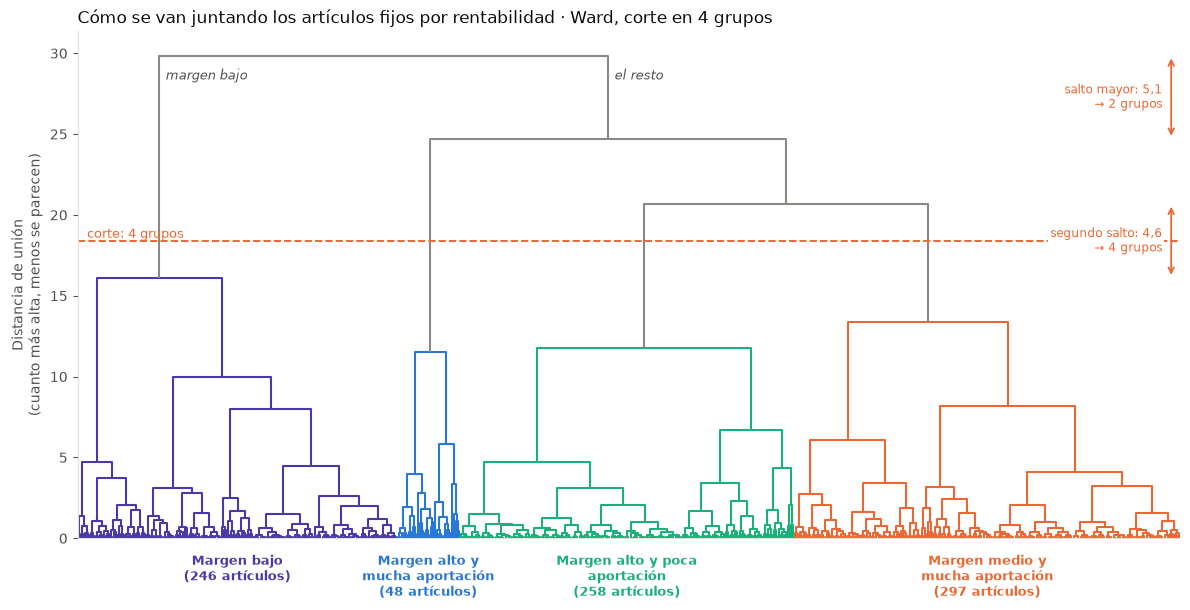

   Altura a la que se completa cada grupo (cuanto más baja, más se parecen sus artículos):
      0 · Margen alto y mucha aportación   11,5
      2 · Margen alto y poca aportación    11,7
      1 · Margen medio y mucha aportación  13,4
      3 · Margen bajo                      16,1
   El corte está en 18,4: el grupo que se completa más cerca de él es el más
   mezclado, y el primero que se partiría si se cortara más abajo.


In [6]:
import textwrap

enlace_r = ag.enlace_jerarquico(Z_r, "ward")
saltos_r = ag.saltos_de_union(enlace_r, 10)
display(saltos_r.round(2))

por_salto = saltos_r["salto"].sort_values(ascending=False)
k_1, k_2 = int(por_salto.index[0]), int(por_salto.index[1])
K_R = 4
corte = saltos_r.loc[K_R, ["union_que_los_junta", "union_anterior"]].mean()
etiquetas_r = ag.ordenar_por_margen_euros(ag.jerarquico(Z_r, K_R)[0], r)
et_filas = etiquetas_r.loc[Z_r.index].to_numpy()

# Nombres por las dos variables de la agrupación; §6 comprueba que encajan con los números.
NOMBRES = {0: "Margen alto y mucha aportación", 1: "Margen medio y mucha aportación",
           2: "Margen alto y poca aportación", 3: "Margen bajo"}

fig, ax = plt.subplots(figsize=(12, 6.2))
arbol = dibujar_dendrograma(enlace_r, ax=ax, no_labels=True,
                            link_color_func=ag.colores_dendrograma(enlace_r, et_filas, PALETA, GRIS))
x_hoja = 5 + 10 * np.arange(len(arbol["leaves"]))
xmax = ax.get_xlim()[1]

# El corte
ax.axhline(corte, color=NARANJA, linestyle="--", linewidth=1.4)
ax.text(xmax * 0.005, corte, f" corte: {K_R} grupos", va="bottom", fontsize=9, color=NARANJA)

# Nombre y tamaño de cada grupo, bajo su color
grupo_hoja = et_filas[arbol["leaves"]]
for g in range(K_R):
    xs = x_hoja[grupo_hoja == g]
    ax.text(xs.mean(), -0.03, "\n".join(textwrap.wrap(NOMBRES[g], 18)) + f"\n({len(xs)} artículos)",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9,
            color=PALETA[g], fontweight="bold")

# Qué separa la unión de más arriba
arriba_del_todo = int(np.argmax([max(d) for d in arbol["dcoord"]]))
x_izq, x_der = arbol["icoord"][arriba_del_todo][0], arbol["icoord"][arriba_del_todo][3]
tope = enlace_r[:, 2].max()
dos = ag.jerarquico(Z_r, 2)[0].loc[Z_r.index].to_numpy()
dos_hoja = dos[arbol["leaves"]]
lado = {c: x_hoja[dos_hoja == c].mean() for c in np.unique(dos)}
izq = min(lado, key=lado.get)
# Se rotula por el margen %, que es lo que separa esa unión (§7ter): un lado es
# el grupo de margen bajo entero y el otro, todo lo demás.
media = pd.Series(r.loc[Z_r.index, "margen_pct"].to_numpy()).groupby(dos).mean()
for c, x in ((izq, x_izq), (max(lado, key=lado.get), x_der)):
    ax.text(x + xmax * 0.006, tope - 0.8,
            "el resto" if media[c] == media.max() else "margen bajo",
            ha="left", va="top", fontsize=9, color=TINTA2, style="italic")

# Los dos saltos mayores
for k, rotulo in ((k_1, "salto mayor"), (k_2, "segundo salto")):
    alto, bajo = saltos_r.loc[k, ["union_que_los_junta", "union_anterior"]]
    x = xmax * 0.992
    ax.annotate("", xy=(x, alto), xytext=(x, bajo),
                arrowprops=dict(arrowstyle="<->", color=NARANJA, lw=1.3))
    ax.text(x - xmax * 0.008, (alto + bajo) / 2, f"{rotulo}: {num(alto - bajo, 1)}\n→ {k} grupos",
            ha="right", va="center", fontsize=8.5, color=NARANJA,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

ax.set_ylabel("Distancia de unión\n(cuanto más alta, menos se parecen)")
ax.set_title("Cómo se van juntando los artículos fijos por rentabilidad · Ward, corte en 4 grupos",
             loc="left", fontsize=12, color=TINTA)
ax.grid(False)
fig.tight_layout()
guardar(fig, "rentabilidad-dendrograma")
plt.show()

cierre = ag.altura_de_cierre(enlace_r, et_filas)
print("   Altura a la que se completa cada grupo (cuanto más baja, más se parecen sus artículos):")
for g in cierre.sort_values().index:
    print(f"      {g} · {NOMBRES[g]:<32} {num(cierre[g], 1)}")
print(f"   El corte está en {num(corte, 1)}: el grupo que se completa más cerca de él es el más")
print("   mezclado, y el primero que se partiría si se cortara más abajo.")

El salto mayor está en k = 2 (5,14); el segundo, en k = 4 (4,57).

**Se corta en cuatro grupos, en el segundo salto** (4,57, justo detrás del
5,14 de k = 2). El salto mayor deja dos grupos: **el de margen bajo, entero,
contra todo lo demás** (el apartado 7ter lo estudia aparte). Cortar en cuatro
no pierde ese grupo —son los mismos artículos— y añade dos separaciones útiles
para la tienda: el grupo pequeño de **margen alto y mucha aportación**, casi
todo frescos, y la diferencia entre los artículos del resto que **aportan
mucho** y los que **aportan poco**.

## 6 · Los cuatro grupos

Los grupos se numeran **de mayor a menor margen medio en euros por artículo**, para que
la lectura no dependa de la numeración del algoritmo. Los nombres son una
propuesta de lectura, y la celda comprueba que siguen encajando con los números.

In [7]:
perfil_r = ag.perfilar_rentabilidad(etiquetas_r, r, meta)
display(perfil_r.round(2))

# Los nombres (definidos en §5) son lectura, no cálculo: si los datos cambian, esto avisa.
mediana_eur = perfil_r["margen_euros_mediano"]
assert perfil_r["margen_pct"].idxmax() == 0, "El grupo 0 ya no tiene el margen % más alto: revisar NOMBRES"
assert perfil_r["margen_pct"].idxmin() == 3, "El grupo 3 ya no tiene el margen % más bajo: revisar NOMBRES"
assert min(mediana_eur[0], mediana_eur[1]) > max(mediana_eur[2], mediana_eur[3]), \
    "Los grupos 0 y 1 ya no son los de más aportación: revisar NOMBRES"

for g in range(K_R):
    f = perfil_r.loc[g]
    print(f"   {g} · {NOMBRES[g]:<32} {int(f['articulos']):3d} art. · margen {num(f['margen_pct'], 1)} % · "
          f"{num(f['cuota_margen_euros_pct'], 1)} % del margen en euros · {num(f['cuota_venta_pct'], 1)} % de la venta")

,articulos,margen_pct,margen_mediano,margen_euros_mediano,margen_euros,cuota_margen_euros_pct,cuota_venta_pct,dpto_dominante
grupo,,,,,,,,
0,48,"35,23","37,21","1.686,16","123.634,49","38,40","31,35",CARNICERIA
1,297,"27,74","27,18","356,28","130.878,61","40,65","42,14",ULTRAMARINOS
2,258,"29,77","29,78","133,95","34.578,95","10,74","10,38",ULTRAMARINOS
3,246,"18,22","23,04","95,72","32.898,82","10,22","16,13",ULTRAMARINOS


   0 · Margen alto y mucha aportación    48 art. · margen 35,2 % · 38,4 % del margen en euros · 31,4 % de la venta
   1 · Margen medio y mucha aportación  297 art. · margen 27,7 % · 40,6 % del margen en euros · 42,1 % de la venta
   2 · Margen alto y poca aportación    258 art. · margen 29,8 % · 10,7 % del margen en euros · 10,4 % de la venta
   3 · Margen bajo                      246 art. · margen 18,2 % · 10,2 % del margen en euros · 16,1 % de la venta


  guardada 05-rentabilidad-grupos.png / .svg


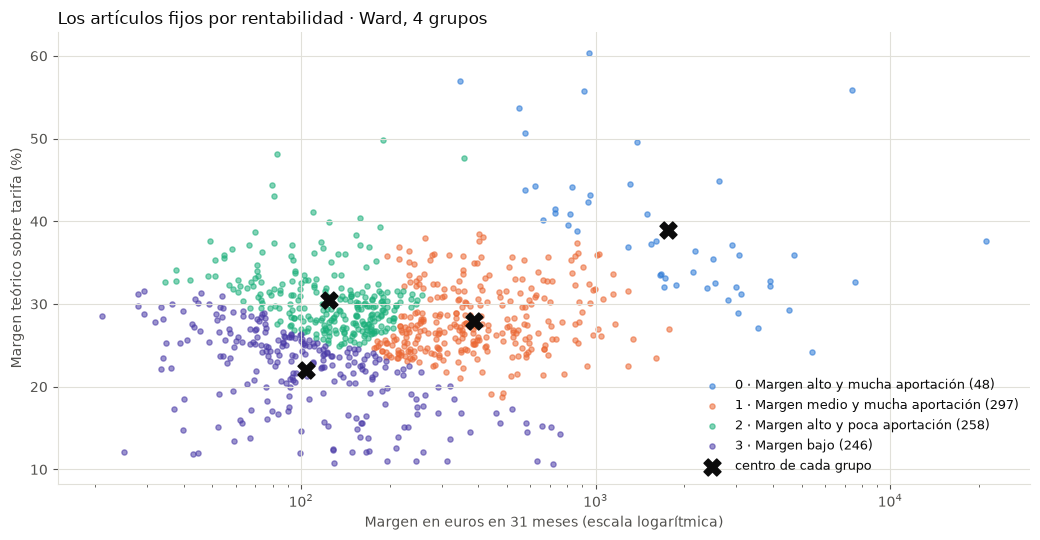

In [8]:
fig, ax = plt.subplots(figsize=(10.5, 5.5))
for g in range(K_R):
    miembros = etiquetas_r.index[etiquetas_r == g]
    ax.scatter(r.loc[miembros, "margen_euros"], r.loc[miembros, "margen_pct"], s=14,
               alpha=0.55, color=PALETA[g], label=f"{g} · {NOMBRES[g]} ({len(miembros)})")
centros_r = M.groupby(etiquetas_r).mean()
ax.scatter(np.exp(centros_r["log_margen_euros"]), centros_r["margen_pct"], marker="X",
           s=150, color=TINTA, zorder=5, label="centro de cada grupo")
ax.set_xscale("log")
ax.set_xlabel("Margen en euros en 31 meses (escala logarítmica)")
ax.set_ylabel("Margen teórico sobre tarifa (%)")
ax.set_title("Los artículos fijos por rentabilidad · Ward, 4 grupos", loc="left",
             fontsize=12, color=TINTA)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
guardar(fig, "rentabilidad-grupos")
plt.show()

**La misma figura, en las variables tipificadas.** La de arriba va en
unidades originales —margen en % y margen en euros— para que se lea, pero
**Ward no agrupa ahí**: agrupa sobre las dos variables tipificadas (media 0 y
desviación 1), donde las dos pesan lo mismo. Esta es la figura en ese espacio,
con los dos ejes en la misma escala.

  guardada 05-rentabilidad-grupos-tipificadas.png / .svg


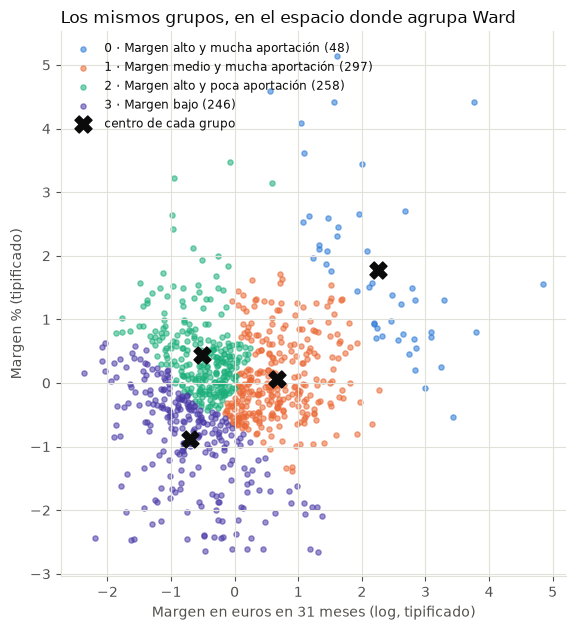

Desviación típica de cada variable tipificada: margen % 1,00, margen en euros 1,00
Correlación entre las dos: 0,226


In [9]:
fig, ax = plt.subplots(figsize=(8, 6.4))
for g in range(K_R):
    miembros = etiquetas_r.index[etiquetas_r == g]
    ax.scatter(Z_r.loc[miembros, "log_margen_euros"], Z_r.loc[miembros, "margen_pct"], s=14,
               alpha=0.55, color=PALETA[g], label=f"{g} · {NOMBRES[g]} ({len(miembros)})")
centros_z = Z_r.groupby(etiquetas_r).mean()
ax.scatter(centros_z["log_margen_euros"], centros_z["margen_pct"], marker="X",
           s=150, color=TINTA, zorder=5, label="centro de cada grupo")
ax.set_aspect("equal")
ax.set_xlabel("Margen en euros en 31 meses (log, tipificado)")
ax.set_ylabel("Margen % (tipificado)")
ax.set_title("Los mismos grupos, en el espacio donde agrupa Ward", loc="left",
             fontsize=12, color=TINTA)
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.tight_layout()
guardar(fig, "rentabilidad-grupos-tipificadas")
plt.show()

print("Desviación típica de cada variable tipificada:",
      ", ".join(f"{NOMBRE_VAR[c]} {num(Z_r[c].std(ddof=0), 2)}" for c in Z_r.columns))
print(f"Correlación entre las dos: {num(Z_r.corr().iloc[0, 1], 3)}")

Las dos variables pesan lo mismo: misma escala (desviación 1) y poca
correlación, así que el agrupamiento no es 'en una sola variable'. Lo que se
ve es que los grupos se separan sobre todo a lo largo del margen en euros,
y el margen % aparta el grupo de margen bajo por debajo.

## 7 · Contraste con k-means

k-means elige su número de grupos con tres criterios:

- el **codo**: la suma de distancias de cada artículo al centro de su grupo,
  que siempre baja al añadir grupos; se busca dónde deja de bajar mucho;
- la **silueta** media: lo bien colocado que está cada artículo en su grupo
  frente al grupo vecino, de −1 a 1;
- el ***gap statistic***: cuánto mejor se agrupan estos datos que unos datos
  sin ninguna estructura.

Aquí sirven para **contrastar el dendrograma**: si hubiera grupos naturales,
los tres deberían señalarlos. Después se agrupa con k-means en los mismos
cuatro grupos y se compara con Ward.

**Los grupos se comparan por contenido, no por número.** La numeración de cada
algoritmo es arbitraria, así que cada grupo de k-means se **empareja con el
grupo de Ward con el que comparte más artículos** (`ag.emparejar`), y la
**coincidencia** es la diagonal de la tabla cruzada. Emparejarlos por número
daría una coincidencia falsa: los dos grupos de poca aportación tienen un
margen en euros muy parecido y cada algoritmo los ordena al revés.

,inercia,silueta
k,,
2,"1.092,03","0,38"
3,"806,39","0,31"
4,"623,50","0,33"
5,"523,54","0,32"
6,"441,39","0,34"
7,"377,48","0,33"
8,"330,79","0,34"
9,"294,40","0,33"
10,"260,13","0,34"


,log_W,E_log_W,gap,error_tipico
k,,,,
1,"5,89","6,72","0,83","0,01"
2,"5,67","6,34","0,68","0,01"
3,"5,51","6,18","0,67","0,01"
4,"5,38","6,02","0,64","0,01"
5,"5,28","5,89","0,61","0,01"
6,"5,21","5,78","0,56","0,01"
7,"5,13","5,70","0,57","0,01"
8,"5,06","5,63","0,57","0,01"
9,"5,00","5,57","0,57","0,01"


  guardada 05-rentabilidad-kmeans-eleccion-de-k.png / .svg


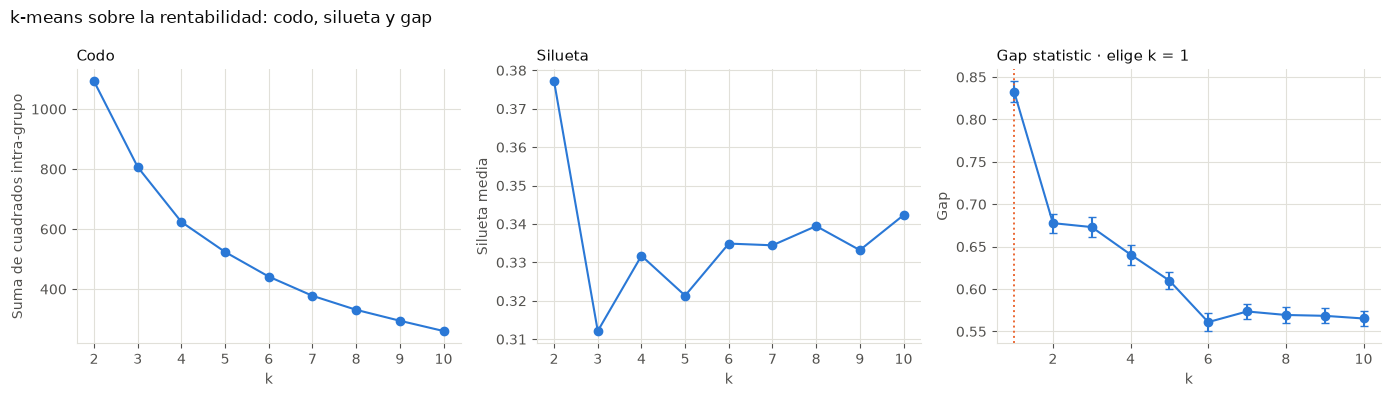


Ward (filas) contra k-means con 4 grupos (columnas):


k-means,0,1,2,3
Ward,,,,
0,48,0,0,0
1,39,251,4,3
2,2,57,199,0
3,0,9,111,126


   Qué parte de cada grupo de Ward cae en el mismo grupo de k-means:
      0 · Margen alto y mucha aportación    100 %
      1 · Margen medio y mucha aportación    85 %
      2 · Margen alto y poca aportación      77 %
      3 · Margen bajo                        51 %

   Los grupos que se quedan en su sitio con los dos algoritmos son el núcleo
   firme; los que se reparten marcan fronteras blandas.


In [10]:
sel_km = ag.elegir_k(Z_r, range(2, 11))
gap_r, k_gap = ag.gap_estadistico(Z_r.to_numpy())
display(sel_km.round(3))
display(gap_r.round(3))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
ax1.plot(sel_km.index, sel_km["inercia"], marker="o", color=AZUL)
ax1.set_xlabel("k")
ax1.set_ylabel("Suma de cuadrados intra-grupo")
ax1.set_title("Codo", loc="left", fontsize=11, color=TINTA)
ax2.plot(sel_km.index, sel_km["silueta"], marker="o", color=AZUL)
ax2.set_xlabel("k")
ax2.set_ylabel("Silueta media")
ax2.set_title("Silueta", loc="left", fontsize=11, color=TINTA)
ax3.errorbar(gap_r.index, gap_r["gap"], yerr=gap_r["error_tipico"], marker="o",
             color=AZUL, capsize=3)
ax3.axvline(k_gap, color=NARANJA, linestyle=":", linewidth=1.4)
ax3.set_xlabel("k")
ax3.set_ylabel("Gap")
ax3.set_title(f"Gap statistic · elige k = {k_gap}", loc="left", fontsize=11, color=TINTA)
fig.suptitle("k-means sobre la rentabilidad: codo, silueta y gap",
             x=0.01, ha="left", fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "rentabilidad-kmeans-eleccion-de-k")
plt.show()

k_sil = int(sel_km["silueta"].idxmax())
resto = sel_km.loc[sel_km.index > k_sil, "silueta"]
print()

km_r = ag.emparejar(etiquetas_r, ag.agrupar(Z_r, K_R)[0])
ct_km = pd.crosstab(etiquetas_r.rename("Ward"), km_r.rename("k-means"))
print(f"Ward (filas) contra k-means con {K_R} grupos (columnas):")
display(ct_km)

centros_km = Z_r.groupby(km_r).transform("mean")
dentro = ((Z_r - centros_km) ** 2).to_numpy().sum()
total = ((Z_r - Z_r.mean()) ** 2).to_numpy().sum()
se_queda = pd.Series(np.diag(ct_km.to_numpy()) / ct_km.sum(axis=1).to_numpy(), index=ct_km.index)

print("   Qué parte de cada grupo de Ward cae en el mismo grupo de k-means:")
for g in range(K_R):
    print(f"      {g} · {NOMBRES[g]:<32} {num(100 * se_queda[g], 0):>4} %")
print()
print("   Los grupos que se quedan en su sitio con los dos algoritmos son el núcleo")
print("   firme; los que se reparten marcan fronteras blandas.")

Silueta: máxima en k = 2 (0,377); de ahí en adelante,
entre 0,312 y 0,342.
Gap: elige k = 1.
No hay más estructura de grupos que en datos sin estructura: el margen %
y el margen en euros forman un continuo. Los cuatro grupos del dendrograma son una
segmentación útil, no tipos de artículo que existan solos.

K-means con 4 grupos: between_SS / total_SS = 63,3 %
(la parte de la variabilidad que explican los grupos)
Coincidencia con Ward: 73,5 %

## 7bis · Contraste con mixturas gaussianas

Un segundo método no jerárquico con k = 4, para ver si identifica los mismos
grupos.

**Qué hacen.** Suponen que los artículos vienen de varias nubes con forma de
campana (normales) y estiman cuántas hay, dónde está cada una y qué forma
tiene. Cada artículo sale con **la probabilidad de pertenecer a cada nube**, no
solo con un grupo: es lo que añaden sobre k-means.

**Cómo eligen el número de grupos: el BIC**, que premia el ajuste a los datos y
castiga el exceso de parámetros. Se prueban de 1 a 9 grupos y cuatro formas de
nube:

| Forma (`scikit-learn`) | Equivalente en `Mclust` (R) | Qué supone |
|---|---|---|
| `full` | VVV | Cada nube con su tamaño, forma y orientación |
| `tied` | EEE | Todas las nubes con la misma forma |
| `diag` | VVI | Nubes alineadas con los ejes |
| `spherical` | VII | Nubes redondas, cada una de su tamaño |

*En `scikit-learn` gana el BIC **más bajo**; `Mclust` lo da con el signo
cambiado y gana el más alto. Es el mismo criterio.*

,VVV,EEE,VVI,VII
k,,,,
1,"4.807,90","4.807,90","4.845,70","4.838,90"
2,"4.659,40","4.707,00","4.687,90","4.679,00"
3,"4.677,10","4.729,50","4.652,60","4.672,00"
4,"4.687,80","4.710,20","4.665,30","4.656,10"
5,"4.697,00","4.674,30","4.664,50","4.663,00"
6,"4.732,50","4.675,00","4.698,30","4.675,40"
7,"4.766,50","4.693,30","4.725,60","4.696,50"
8,"4.802,90","4.695,20","4.751,80","4.713,20"
9,"4.827,20","4.709,00","4.783,90","4.734,70"


  guardada 05-rentabilidad-mixturas-bic.png / .svg


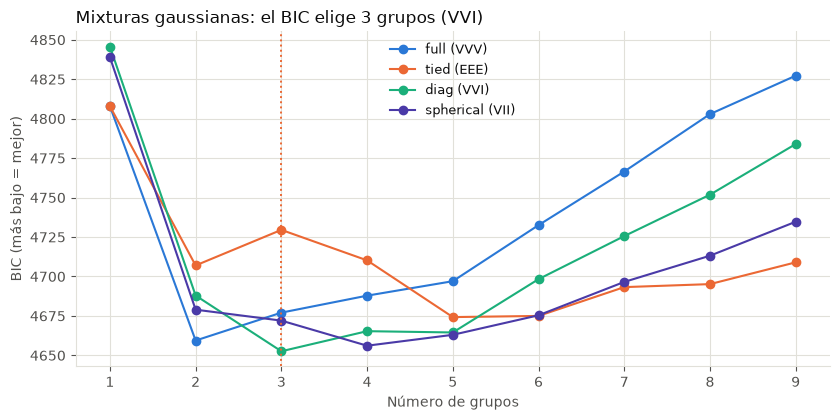

   El mejor BIC para cada número de grupos, y cuánto le separa del elegido:
      1 grupos: 4.807,9  (+155,3)
      2 grupos: 4.659,4  (+6,8)
      3 grupos: 4.652,6  (+0,0)
      4 grupos: 4.656,1  (+3,5)
      5 grupos: 4.663,0  (+10,4)


In [11]:
TIPOS_MCLUST = {"full": "VVV", "tied": "EEE", "diag": "VVI", "spherical": "VII"}

bic_r, (k_bic, tipo_bic) = ag.mixturas_bic(Z_r)
display(bic_r.rename(columns=TIPOS_MCLUST).round(1))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
for tipo, color in zip(bic_r.columns, PALETA):
    ax.plot(bic_r.index, bic_r[tipo], marker="o", color=color,
            label=f"{tipo} ({TIPOS_MCLUST[tipo]})")
ax.axvline(k_bic, color=NARANJA, linestyle=":", linewidth=1.4)
ax.set_xlabel("Número de grupos")
ax.set_ylabel("BIC (más bajo = mejor)")
ax.set_title(f"Mixturas gaussianas: el BIC elige {k_bic} grupos ({TIPOS_MCLUST[tipo_bic]})",
             loc="left", fontsize=12, color=TINTA)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
guardar(fig, "rentabilidad-mixturas-bic")
plt.show()

mejor_por_k = bic_r.min(axis=1)
print("   El mejor BIC para cada número de grupos, y cuánto le separa del elegido:")
for k in range(1, 6):
    print(f"      {k} grupos: {num(mejor_por_k[k], 1)}  (+{num(mejor_por_k[k] - mejor_por_k[k_bic], 1)})")

De 1 a 2 grupos el BIC mejora 149 puntos; entre 2, 3 y 4, solo unos
pocos. Las mixturas separan claramente 'un grupo' de 'varios', pero no
distinguen si son 2, 3 o 4: lo mismo que ya decían la silueta y el gap.

El BIC elige 3 grupos (forma vvi), pero sin claridad.

In [12]:
tipo_4 = bic_r.loc[K_R].idxmin()   # la mejor forma con 4 grupos, como Mclust(G = 4)
mix_r, prob_r = ag.mixtura(Z_r, K_R, tipo_4)
mix_r = ag.emparejar(etiquetas_r, mix_r)

ct_mix = pd.crosstab(etiquetas_r.rename("Ward"), mix_r.rename("mixtura"))
print(f"Ward (filas) contra la mixtura de {K_R} grupos, forma {TIPOS_MCLUST[tipo_4]} (columnas):")
display(ct_mix)

se_queda_mix = pd.Series(np.diag(ct_mix.to_numpy()) / ct_mix.sum(axis=1).to_numpy(), index=ct_mix.index)
dudosos = (prob_r < 0.7).mean()

print("   Qué parte de cada grupo de Ward cae en el mismo grupo, con cada método:")
print(f"      {'':<36}{'k-means':>9}{'mixtura':>9}")
for g in range(K_R):
    print(f"      {g} · {NOMBRES[g]:<32}{num(100 * se_queda[g], 0):>8} %{num(100 * se_queda_mix[g], 0):>7} %")
print()
medios = pd.concat([se_queda.loc[[1, 2]], se_queda_mix.loc[[1, 2]]])

Ward (filas) contra la mixtura de 4 grupos, forma VII (columnas):


mixtura,0,1,2,3
Ward,,,,
0,48,0,0,0
1,41,251,2,3
2,10,29,219,0
3,0,13,148,85


   Qué parte de cada grupo de Ward cae en el mismo grupo, con cada método:
                                            k-means  mixtura
      0 · Margen alto y mucha aportación       100 %    100 %
      1 · Margen medio y mucha aportación       85 %     85 %
      2 · Margen alto y poca aportación         77 %     85 %
      3 · Margen bajo                           51 %     35 %



Coincidencia con ward: 71,0 % (k-means, §7: 73,5 %).

39 % de los artículos no pertenecen claramente a ningún grupo
(probabilidad del grupo asignado por debajo de 0,7). Es la medida directa de
que la rentabilidad es un continuo: muchos artículos están en la frontera.

Los dos métodos no jerárquicos
identifican los cuatro grupos en su mayor parte. El de margen alto y mucha
aportación, entero; los grupos 1 y 2, entre el 77 y el 85 %.
El más blando es el de margen bajo (51 % y 35 %): su frontera con el
de margen alto y poca aportación es la que menos se sostiene.

**Los tres métodos, uno al lado del otro.** Los mismos artículos, en las
variables tipificadas, coloreados por el grupo que les da cada método con
k = 4. Los grupos de k-means y de la mixtura están emparejados con los de Ward
por contenido (`ag.emparejar`), así que cada color es el mismo grupo en los
tres dibujos.

  guardada 05-rentabilidad-tres-metodos.png / .svg


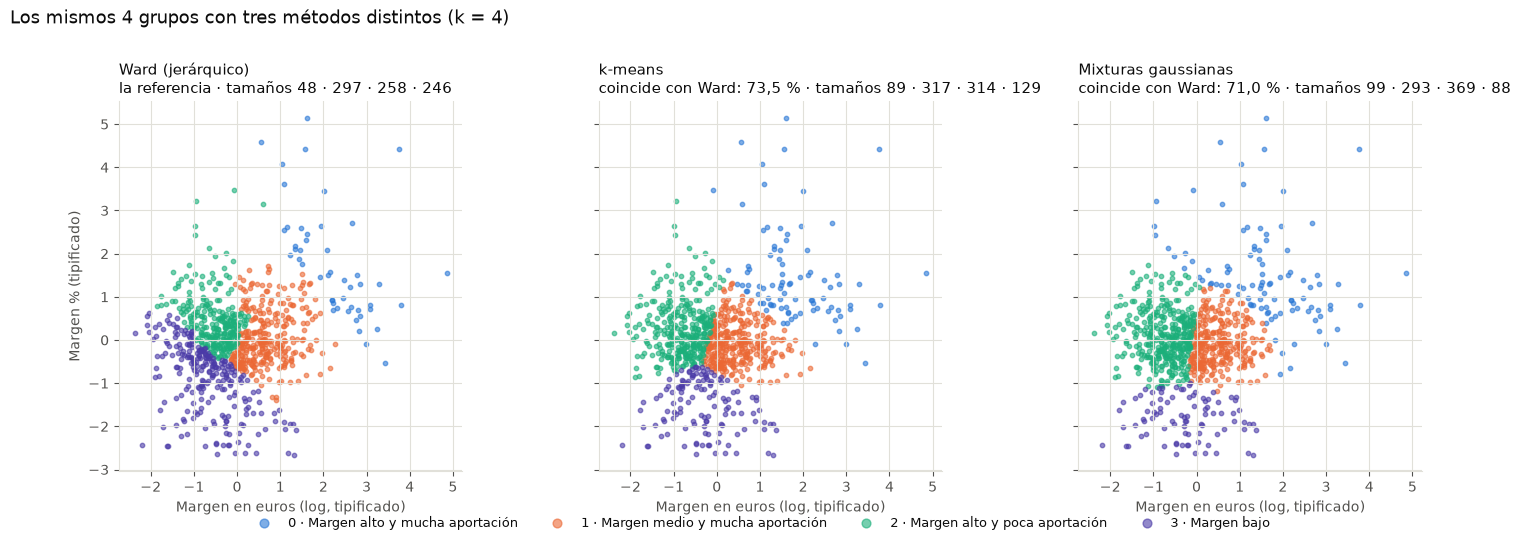

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharex=True, sharey=True)
metodos = [("Ward (jerárquico)", etiquetas_r), ("k-means", km_r), ("Mixturas gaussianas", mix_r)]
for ax, (titulo, et) in zip(axes, metodos):
    for g in range(K_R):
        miembros = et.index[et == g]
        ax.scatter(Z_r.loc[miembros, "log_margen_euros"], Z_r.loc[miembros, "margen_pct"], s=10,
                   alpha=0.6, color=PALETA[g], label=f"{g} · {NOMBRES[g]}")
    sub = ("la referencia" if et is etiquetas_r
           else f"coincide con Ward: {num(100 * ag.coincidencia(etiquetas_r, et), 1)} %")
    tamanos = " · ".join(str(int((et == g).sum())) for g in range(K_R))
    ax.set_title(f"{titulo}\n{sub} · tamaños {tamanos}", loc="left", fontsize=10.5, color=TINTA)
    ax.set_aspect("equal")
    ax.set_xlabel("Margen en euros (log, tipificado)")
axes[0].set_ylabel("Margen % (tipificado)")
manejadores, rotulos = axes[0].get_legend_handles_labels()
fig.legend(manejadores, rotulos, loc="lower center", ncol=K_R, frameon=False, fontsize=9.5,
           markerscale=2)
fig.suptitle(f"Los mismos {K_R} grupos con tres métodos distintos (k = {K_R})", x=0.01,
             ha="left", fontsize=13, color=TINTA)
fig.tight_layout(rect=(0, 0.06, 1, 0.93))
guardar(fig, "rentabilidad-tres-metodos")
plt.show()

g0 = (etiquetas_r == 0).sum()

El grupo de margen alto y mucha aportación: sus 48 artículos caen juntos con los
tres métodos; k-means y la mixtura le añaden 41 y 51 artículos cercanos.
El de margen bajo es el que más cambia: en k-means y en la mixtura, su parte
de menos margen en euros y margen % intermedio pasa al grupo de margen alto y
poca aportación, y el margen bajo se queda con los de margen % más bajo.

## 7ter · ¿Y con dos grupos? El corte del salto mayor

El salto mayor del dendrograma deja **dos grupos**, y dos grupos es también lo
que prefieren la silueta de k-means y, casi empatado, el BIC de las mixturas.
Así que merece la misma revisión que los cuatro: **qué separa, si los otros
métodos lo reproducen y qué le dice a la tienda**:

1. cortar el mismo dendrograma de Ward en 2 (no hay que volver a agrupar);
2. describir los dos grupos;
3. ver cómo encajan en los cuatro;
4. contrastar con k-means y con la mixtura gaussiana con k = 2;
5. dibujarlo.

*En la figura, los colores de k-means y de la mixtura son el grupo de Ward con
el que cada uno se empareja.*

In [14]:
K2 = 2
etiquetas_2 = ag.ordenar_por_margen_euros(ag.jerarquico(Z_r, K2)[0], r)
perfil_2 = ag.perfilar_rentabilidad(etiquetas_2, r, meta)
NOMBRES_2 = {0: "El resto", 1: "Margen bajo"}
assert perfil_2["margen_pct"].idxmin() == 1, "El grupo 1 ya no es el de margen bajo: revisar NOMBRES_2"
display(perfil_2.round(2))

for g in range(K2):
    f = perfil_2.loc[g]
    print(f"   {g} · {NOMBRES_2[g]:<12} {int(f['articulos']):3d} art. · margen {num(f['margen_pct'], 1)} % · "
          f"{num(f['cuota_margen_euros_pct'], 1)} % del margen en euros · {num(f['cuota_venta_pct'], 1)} % de la venta")

,articulos,margen_pct,margen_mediano,margen_euros_mediano,margen_euros,cuota_margen_euros_pct,cuota_venta_pct,dpto_dominante
grupo,,,,,,,,
0,603,"30,79","28,86","233,77","289.092,05","89,78","83,87",ULTRAMARINOS
1,246,"18,22","23,04","95,72","32.898,82","10,22","16,13",ULTRAMARINOS


   0 · El resto     603 art. · margen 30,8 % · 89,8 % del margen en euros · 83,9 % de la venta
   1 · Margen bajo  246 art. · margen 18,2 % · 10,2 % del margen en euros · 16,1 % de la venta


Con dos grupos, ward separa el margen bajo del resto. Los dos grupos se
diferencian sobre todo en el margen %: 18,2 % frente a 30,8 %.

In [15]:
cruce_2_4 = pd.crosstab(etiquetas_r.map(NOMBRES).rename("con 4 grupos"),
                        etiquetas_2.map(NOMBRES_2).rename("con 2 grupos"))
display(cruce_2_4)

mismo = (etiquetas_2 == 1).equals(etiquetas_r == 3)

con 2 grupos,El resto,Margen bajo
con 4 grupos,,
Margen alto y mucha aportación,48,0
Margen alto y poca aportación,258,0
Margen bajo,0,246
Margen medio y mucha aportación,297,0


El grupo de margen bajo es el mismo con 2 y con 4 grupos
Los otros tres grupos de k = 4 son la partición del 'resto'. Pasar de 2 a 4
no mueve el margen bajo: separa dentro del resto el grupo de frescos de margen
alto y mucha aportación, y lo que aporta mucho de lo que aporta poco.

  guardada 05-rentabilidad-dos-grupos.png / .svg


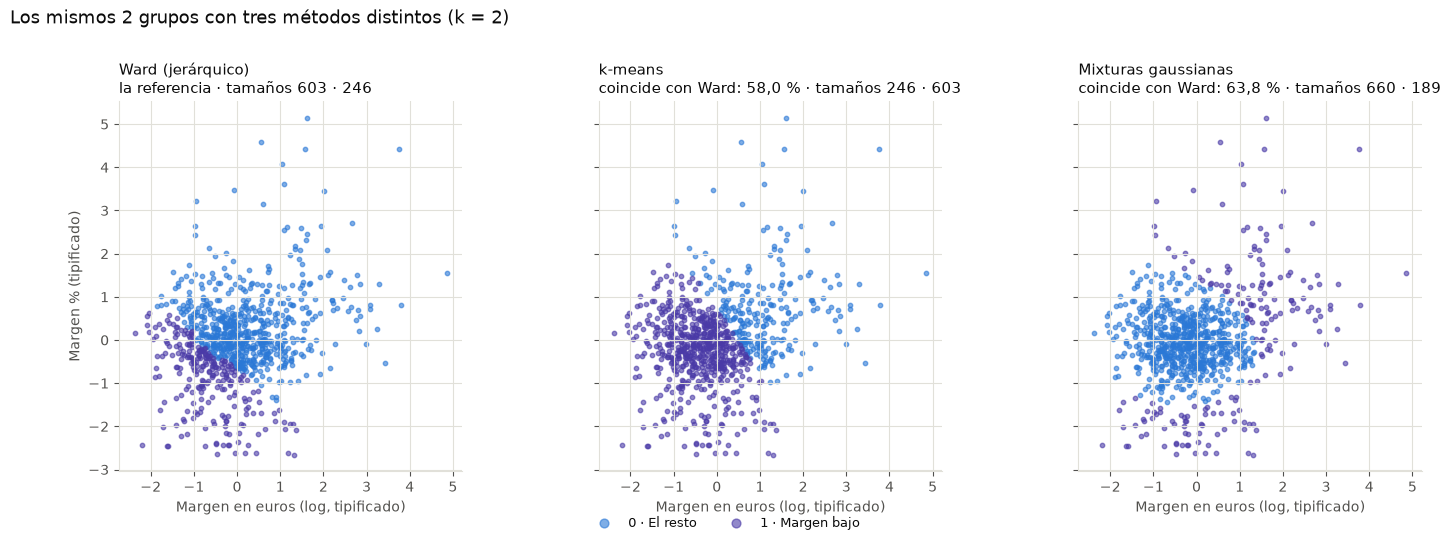

   Silueta de k-means con 2 grupos: 0,377 (con 4: 0,332)
   Artículos sin grupo claro en la mixtura (prob. < 0,7): 15 % (con 4 grupos: 39 %)


In [16]:
km_2 = ag.emparejar(etiquetas_2, ag.agrupar(Z_r, K2)[0])
tipo_2 = bic_r.loc[K2].idxmin()   # la mejor forma con 2 grupos, como Mclust(G = 2)
mix_2, prob_2 = ag.mixtura(Z_r, K2, tipo_2)
mix_2 = ag.emparejar(etiquetas_2, mix_2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharex=True, sharey=True)
metodos_2 = [("Ward (jerárquico)", etiquetas_2), ("k-means", km_2), ("Mixturas gaussianas", mix_2)]
COLORES_2 = [AZUL, VIOLETA]
for ax, (titulo, et) in zip(axes, metodos_2):
    for g in range(K2):
        miembros = et.index[et == g]
        ax.scatter(Z_r.loc[miembros, "log_margen_euros"], Z_r.loc[miembros, "margen_pct"], s=10,
                   alpha=0.6, color=COLORES_2[g], label=f"{g} · {NOMBRES_2[g]}")
    sub = ("la referencia" if et is etiquetas_2
           else f"coincide con Ward: {num(100 * ag.coincidencia(etiquetas_2, et), 1)} %")
    tamanos = " · ".join(str(int((et == g).sum())) for g in range(K2))
    ax.set_title(f"{titulo}\n{sub} · tamaños {tamanos}", loc="left", fontsize=10.5, color=TINTA)
    ax.set_aspect("equal")
    ax.set_xlabel("Margen en euros (log, tipificado)")
axes[0].set_ylabel("Margen % (tipificado)")
manejadores, rotulos = axes[0].get_legend_handles_labels()
fig.legend(manejadores, rotulos, loc="lower center", ncol=K2, frameon=False, fontsize=9.5,
           markerscale=2)
fig.suptitle(f"Los mismos {K2} grupos con tres métodos distintos (k = {K2})", x=0.01,
             ha="left", fontsize=13, color=TINTA)
fig.tight_layout(rect=(0, 0.06, 1, 0.93))
guardar(fig, "rentabilidad-dos-grupos")
plt.show()

c_km2 = ag.coincidencia(etiquetas_2, km_2)
c_mix2 = ag.coincidencia(etiquetas_2, mix_2)
print(f"   Silueta de k-means con {K2} grupos: {num(sel_km.loc[K2, 'silueta'], 3)} (con {K_R}: "
      f"{num(sel_km.loc[K_R, 'silueta'], 3)})")
print(f"   Artículos sin grupo claro en la mixtura (prob. < 0,7): {num(100 * (prob_2 < 0.7).mean(), 0)} % "
      f"(con {K_R} grupos: {num(100 * (prob_r < 0.7).mean(), 0)} %)")

Con dos grupos, los métodos coinciden menos con ward: k-means 58,0 %, mixtura 63,8 %
(con 4 grupos: 73,5 % y 71,0 %).
Se ve en la figura que cada método parte en dos de una forma distinta:
- Ward separa por abajo: los de margen % más bajo.
- K-means parte en diagonal: los que tienen a la vez más margen % y más
margen en euros, contra todo lo demás.
- La mixtura ni siquiera parte por la rentabilidad: separa un núcleo denso de
artículos 'normales' de los que están lejos del centro en cualquier dirección.
No hay una sola forma natural de partir en dos. Con dos grupos hay menos
artículos dudosos, pero ningún acuerdo sobre cuáles son esos dos grupos.

### Qué aporta cada corte a la tienda

| | Con 2 grupos | Con 4 grupos |
|---|---|---|
| **Qué separa** | Margen bajo contra el resto | Margen bajo, frescos de margen alto y mucha aportación, y el resto partido en mucha y poca aportación |
| **Pregunta que contesta** | *¿Qué artículos tienen el margen claramente por debajo?* | Esa misma, más *¿dónde está el margen en euros?* y *¿qué artículos aportan poco?* |
| **Acuerdo entre métodos** | Menor: cada método parte de una forma distinta | Mayor, en torno al 70 % |
| **Artículos dudosos (mixtura)** | Menos | Más |

**Los dos cortes son defendibles; se usa el de cuatro porque contesta más
preguntas sin perder la del de dos.** El grupo de margen bajo, que es el único
que existe con dos grupos, sigue entero con cuatro.

## 8 · Qué hay en cada grupo

De qué departamentos son, y cuáles son los artículos que más aportan en cada uno.

In [17]:
d_r = r.join(meta_s[["descripcion", "departamento"]])
d_r["grupo"] = etiquetas_r
display(pd.crosstab(d_r["departamento"], d_r["grupo"].map(lambda g: f"{g} · {NOMBRES[g]}"),
                    margins=True, margins_name="total"))

for g in range(K_R):
    top = d_r[d_r["grupo"] == g].nlargest(5, "margen_euros")
    print(f"\nGrupo {g} · {NOMBRES[g]} — los 5 que más aportan:")
    for _, f in top.iterrows():
        print(f"   {f['descripcion']:<30} {f['departamento']:<22} margen {num(f['margen_pct'], 1):>5} %"
              f"   {num(f['margen_euros'], 0):>7} € de margen")

grupo,0 · Margen alto y mucha aportación,1 · Margen medio y mucha aportación,2 · Margen alto y poca aportación,3 · Margen bajo,total
departamento,,,,,
BAZAR,0,2,1,1,4
BEBIDAS,1,58,37,31,127
CARNICERIA,21,14,2,0,37
CHARCUTERIA CORTE,0,32,9,3,44
CHARCUTERIA L.S,0,7,2,0,9
CONGELADOS,1,12,10,0,23
DEPARTAMENTO NO ESPECIFICADO,0,0,1,1,2
DROGUERIA Y PERFUMERIA,0,27,58,26,111
FRUTAS Y VERDURAS,17,11,5,1,34



Grupo 0 · Margen alto y mucha aportación — los 5 que más aportan:
   BARRA ORIGEN 20 UD             PANADERIA PASTELERIA   margen  37,6 %    21.117 € de margen
   PECHUGA DE POLLO A             CARNICERIA             margen  32,7 %     7.623 € de margen
   CARNE PICADA CERDO KG          CARNICERIA             margen  55,8 %     7.393 € de margen
   CERVEZA COVIRAN LATA           BEBIDAS                margen  24,2 %     5.419 € de margen
   POLLO NUTRAVE KG               CARNICERIA             margen  35,9 %     4.719 € de margen

Grupo 1 · Margen medio y mucha aportación — los 5 que más aportan:
   CINTA DE LOMO SIN              CARNICERIA             margen  27,0 %     1.778 € de margen
   CERVEZA CLASICA                BEBIDAS                margen  23,5 %     1.601 € de margen
   CERVEZA 0.0 TOSTADA            BEBIDAS                margen  25,8 %     1.341 € de margen
   BEBIDA LACTEA C/CAFE           ULTRAMARINOS           margen  22,5 %     1.286 € de margen
   HAMBURGUESAS DE 

## 9 · Cómo se lee, y qué avisos lleva

**Cómo se lee.** Cada grupo tiene una lectura de tienda, y se comprueba en las
tablas de los apartados 6 y 8:

- **Margen alto y mucha aportación** — pocos artículos, casi todos **frescos**
  (carnicería, fruta y verdura, panadería), con más de un tercio del margen en
  euros.
- **Margen medio y mucha aportación** — el grupo más grande, sobre todo
  **lineal envasado** (ultramarinos, bebidas, droguería, charcutería), con un
  margen moderado pero el mayor peso en el margen en euros: muchos artículos,
  cada uno aportando algo.
- **Margen alto y poca aportación** — margen casi tan alto como el primer
  grupo, pero con pocas unidades vendidas por artículo: aporta poco en total
  aunque cada venta deje mucho.
- **Margen bajo** — los **básicos**, con la leche y el aceite a la cabeza; la
  mayoría de los lácteos cae aquí. Pesan más en la venta que en el margen. **Es
  una decisión, no un descuido**: la central recomienda en torno a un 10 % de
  margen en básicos (apartado 9bis).

**Los avisos que acompañan a cualquier cifra de esta parte:**

1. Es **margen teórico sobre tarifa**: sobre el precio al que se compraría hoy,
   no sobre lo que se pagó en cada compra. Y es margen sobre la mercancía, no
   lo que gana la tienda.
2. El margen en euros está **sumado en euros corrientes** de 31 meses.
3. **Hay fichas de coste que nadie actualiza.** En los artículos sin ninguna
   compra ligada a su código, la tarifa es una referencia puesta a mano y puede
   llevar años sin moverse. La celda de abajo los cuenta por grupo.

In [18]:
dudosa = ag.tarifa_congelada(largo).reindex(r.index, fill_value=False)

print(f"Artículos con la tarifa sin moverse en 31 meses y sin ninguna compra ligada: {int(dudosa.sum())}")
for g in range(K_R):
    miembros = etiquetas_r.index[(etiquetas_r == g) & dudosa.reindex(etiquetas_r.index)]
    print(f"   Grupo {g} · {NOMBRES[g]:<32} {len(miembros):3d}"
          + (f"   {', '.join(meta_s.loc[miembros, 'descripcion'])}" if len(miembros) else ""))

Artículos con la tarifa sin moverse en 31 meses y sin ninguna compra ligada: 11
   Grupo 0 · Margen alto y mucha aportación     3   PALOTES C/ACEITE OLIVA, ARREGLO TRASEROS, CARNE PICADA CERDO KG
   Grupo 1 · Margen medio y mucha aportación    1   PAN DE ACEITE 400 GR
   Grupo 2 · Margen alto y poca aportación      6   GALLETAS TOSTA RICA, COLORANTE LA BARRACA, OREGANO LA BARRACA, PIMIENTA NEGRA MOLIDA LA, PIPAS CON SAL 45 GR, PAPEL CIGARRILLOS OCB
   Grupo 3 · Margen bajo                        1   PIPAS G TIJUAN 100 G


Su margen hay que leerlo con reserva: la tarifa no refleja lo que
cuesta hoy comprarlos. No se excluyen —son surtido real—, se señalan.

## 9bis · Contraste con lo que recomienda la central de compras

Dato de la tienda: la central de compras **recomienda un margen de 20-40 % en
general, y de solo un 10 % aproximado en básicos**, con la leche y el aceite
como ejemplos. Es un dato externo para comprobar si el margen bajo de esos
artículos es una decisión de la tienda o un descuido.

**No se contrasta solo sobre los 849 fijos**: la pregunta es sobre el surtido
entero, así que se recalcula el margen de todo `SURTIDO` y se separan leche y
aceite **sin derivados ni conservas** —arroz con leche, atún en aceite o pan de
aceite son otros productos con otro margen— del resto.

In [19]:
sur_completo = cc._surtido(cc.Contexto())
g_cov = ag.clasificar_basicos(sur_completo)

resumen_cov = ag.resumen_recomendacion_coviran(g_cov)
display(resumen_cov.round(2))

print()
rep_cov = ag.representativos_por_banda(g_cov)
display(rep_cov.round(2))

# Las dos cifras del texto de abajo, calculadas aquí.
bas = g_cov[g_cov["basico"]].sort_values("margen_pct", ascending=False)
altos = bas[bas["margen_pct"] > 22]
resto = g_cov[~g_cov["basico"]]
en_banda = resto["margen_pct"].between(20, 40)
print(f"\nBásicos por encima del 22 %: {len(altos)} de {len(bas)}, "
      f"con {num(altos['venta'].sum(), 2)} € de venta en los 31 meses.")
print(f"El margen más alto de los demás básicos: "
      f"{num(bas.loc[bas['margen_pct'] <= 22, 'margen_pct'].max(), 1)} %.")
print(f"Resto del surtido dentro de la banda 20-40 %: {num(100 * en_banda.mean(), 1)} % "
      f"de los artículos y {num(100 * resto.loc[en_banda, 'venta'].sum() / resto['venta'].sum(), 1)} % de la venta.")


,articulos,venta,margen_pct_mediano,margen_pct_ponderado,en_banda_20_40_pct
grupo,,,,,
"básicos (leche, aceite)",59,"84.987,07","14,48","13,18","6,78"
resto del surtido,6588,"1.935.128,52","27,34","29,04","87,58"


,banda,descripcion,departamento,venta,margen_pct
cod_articulo,,,,,
19966,básico (~10 %),ACEITE DE OLIVA VIRGEN,ULTRAMARINOS,"7.320,23","8,33"
420001,básico (~10 %),LECHE ENTERA COVIRAN,ULTRAMARINOS,"6.670,39","10,71"
420004,básico (~10 %),LECHE SEMIDESNATA,ULTRAMARINOS,"5.757,53","10,98"
30362,básico (~10 %),LECHE SEMIDESNATADA,ULTRAMARINOS,"5.264,89","14,32"
400000,básico (~10 %),ACEITE GIRASOL COVIRAN 1,ULTRAMARINOS,"4.667,26","15,16"
14501,"bajo, no básico (<20 %)",ACEITE VIRGEN COOSUR 5 L,ULTRAMARINOS,"8.425,61","7,95"
407045,"bajo, no básico (<20 %)",AZUCAR COVIRAN,ULTRAMARINOS,"3.000,38","17,29"
8609,"bajo, no básico (<20 %)",ACTIMEL FRESA DANONE,LACTEOS,"2.731,90","16,77"
830,"bajo, no básico (<20 %)",AZUCAR BLANQUILLA,ULTRAMARINOS,"2.563,23","18,79"



Básicos por encima del 22 %: 2 de 59, con 20,57 € de venta en los 31 meses.
El margen más alto de los demás básicos: 20,8 %.
Resto del surtido dentro de la banda 20-40 %: 87,6 % de los artículos y 89,3 % de la venta.


**Las dos mitades de la cifra de la tienda se confirman.** Leche y aceite (sin
derivados ni conservas) salen con margen mediano **14,5 %** (ponderado
13,2 %), muy por debajo del resto del catálogo y del mismo orden que el 10 %
citado; solo dos referencias de leche, con venta testimonial, pasan del 22 %.
El resto del surtido tiene mediana **27,3 %** (ponderado 29,0 %) y el
**87,6 %** de sus artículos cae dentro de la banda del 20-40 % (el 89,3 % de la
venta).

**El grupo de margen bajo no tiene margen bajo por descuido**: tiene el margen
que recomienda el proveedor para productos básicos, y la tienda lo sigue. Es
un dato de negocio que valida la segmentación **desde fuera del propio
análisis de grupos**.

**Qué no confirma:** que el 20 % y el 40 % sean los límites exactos —son los que
recuerdan las propietarias— ni si la tienda elige ese margen bajo por
estrategia (atraer clientela) o simplemente sigue la recomendación.

## 10 · De la agrupación a la tienda

La agrupación dice **dónde mirar**. Esta sección lo traduce en tres medidas
que la tienda puede usar, todas con aritmética sobre los mismos datos y sin
modelos nuevos:

1. **Cómo evoluciona el margen de cada grupo**, comparando los mismos meses
   —enero a julio— de cada año, los únicos completos en los tres. Con un
   control: repetirlo **sin las fichas de coste congeladas**, por si la subida
   viniera de ellas.
2. **Cuánto vale un punto de margen en cada grupo**, sobre la venta de los
   últimos 12 meses. *Es una cuenta, no una predicción:* supone que se vende lo
   mismo, y no se sabe cuánto cambiaría la venta al tocar un precio.
3. **Cuánto depende de unos pocos artículos** el grupo que más aporta.

In [20]:
sur_f = ag.surtido_de(r.index)
congelada_fila = sur_f["cod"].map(dudosa).fillna(False).astype(bool)
evol = ag.margen_por_anio(sur_f, etiquetas_r)
evol_sin = ag.margen_por_anio(sur_f[~congelada_fila], etiquetas_r)

tabla_evol = pd.concat({"con todos": evol, "sin fichas congeladas": evol_sin}, axis=1)
tabla_evol.index = [f"{g} · {NOMBRES[g]}" for g in tabla_evol.index]
display(tabla_evol.round(2))

a0, a1 = int(evol.columns.min()), int(evol.columns.max())
print(f"Cambio del margen % entre enero-julio de {a0} y de {a1}, en puntos:")
for g in evol.index:
    print(f"   {g} · {NOMBRES[g]:<32} {num(evol.loc[g, a1] - evol.loc[g, a0], 1, signo=True):>5}"
          f"   sin fichas congeladas {num(evol_sin.loc[g, a1] - evol_sin.loc[g, a0], 1, signo=True):>5}")
if (evol[a1] > evol[a0]).all() and (evol_sin[a1] > evol_sin[a0]).all():
    print("   El margen % sube en los cuatro grupos, también sin las fichas congeladas:")
    print("   la subida no viene de fichas sin actualizar. El porqué —proveedor, precios—")
    print("   no está en el dato.")

con todos              \
anio                                     2024  2025  2026   
0 · Margen alto y mucha aportación      33,24 34,95 37,21   
1 · Margen medio y mucha aportación     26,78 27,66 28,64   
2 · Margen alto y poca aportación       29,45 29,76 30,07   
3 · Margen bajo                         17,59 18,24 19,07   

                                    sin fichas congeladas              
anio                                                 2024  2025  2026  
0 · Margen alto y mucha aportación                  32,21 34,14 36,55  
1 · Margen medio y mucha aportación                 26,79 27,62 28,61  
2 · Margen alto y poca aportación                   29,42 29,74 30,05  
3 · Margen bajo                                     17,59 18,24 19,07

Cambio del margen % entre enero-julio de 2024 y de 2026, en puntos:
   0 · Margen alto y mucha aportación    +4,0   sin fichas congeladas  +4,3
   1 · Margen medio y mucha aportación   +1,9   sin fichas congeladas  +1,8
   2 · Margen alto y poca aportación     +0,6   sin fichas congeladas  +0,6
   3 · Margen bajo                       +1,5   sin fichas congeladas  +1,5
   El margen % sube en los cuatro grupos, también sin las fichas congeladas:
   la subida no viene de fichas sin actualizar. El porqué —proveedor, precios—
   no está en el dato.


In [21]:
u12 = ag.ultimos_12_meses(sur_f, etiquetas_r)
vista = u12.copy()
vista.index = [f"{g} · {NOMBRES[g]}" for g in vista.index]
display(vista.round({"venta": 0, "margen_euros": 0, "margen_pct": 1,
                     "cuota_margen_euros_pct": 1, "un_punto_mas_euros": 0}))

mas, menos = int(u12["un_punto_mas_euros"].idxmax()), int(u12["un_punto_mas_euros"].idxmin())

,meses,venta,margen_euros,margen_pct,cuota_margen_euros_pct,un_punto_mas_euros
0 · Margen alto y mucha aportación,12,"142.832,00","52.585,00","36,80","39,70","1.428,00"
1 · Margen medio y mucha aportación,12,"186.513,00","53.139,00","28,50","40,10","1.865,00"
2 · Margen alto y poca aportación,12,"45.218,00","13.543,00","30,00","10,20","452,00"
3 · Margen bajo,12,"70.432,00","13.211,00","18,80","10,00","704,00"


En los últimos 12 meses, un punto más de margen valdría:
1.865 € al año en el grupo 1 (Margen medio y mucha aportación)
452 € al año en el grupo 2 (Margen alto y poca aportación)
4,1 veces más: revisar precios rinde más donde más se vende.
Es una cuenta con la misma venta: no dice cuánto cambiaría la venta al tocar el precio.

In [22]:
grupo0 = r.loc[etiquetas_r.index[etiquetas_r == 0]].join(meta_s["descripcion"])
diez = grupo0.nlargest(10, "margen_euros")
print(f"Los 10 artículos del grupo 0 ({NOMBRES[0]}) que más margen en euros dejan hacen el")
print(f"{num(100 * diez['margen_euros'].sum() / grupo0['margen_euros'].sum(), 1)} % del margen en euros del grupo "
      f"y el {num(100 * diez['margen_euros'].sum() / r['margen_euros'].sum(), 1)} % del de los "
      f"{len(r)} artículos fijos:\n")
for _, f in diez.iterrows():
    print(f"   {f['descripcion']:<28} margen {num(f['margen_pct'], 1):>5} %   {num(f['margen_euros'], 0):>7} € en 31 meses")

Los 10 artículos del grupo 0 (Margen alto y mucha aportación) que más margen en euros dejan hacen el
52,8 % del margen en euros del grupo y el 20,3 % del de los 849 artículos fijos:

   BARRA ORIGEN 20 UD           margen  37,6 %    21.117 € en 31 meses
   PECHUGA DE POLLO A           margen  32,7 %     7.623 € en 31 meses
   CARNE PICADA CERDO KG        margen  55,8 %     7.393 € en 31 meses
   CERVEZA COVIRAN LATA         margen  24,2 %     5.419 € en 31 meses
   POLLO NUTRAVE KG             margen  35,9 %     4.719 € en 31 meses
   PLATANO SUPER EXTRA          margen  29,2 %     4.552 € en 31 meses
   COSTILLAS DE CERDO           margen  32,8 %     3.899 € en 31 meses
   HUEVOS CLASE L 6 U.          margen  32,2 %     3.895 € en 31 meses
   BARRA DE PAN                 margen  27,1 %     3.561 € en 31 meses
   PALOTES C/ACEITE OLIVA       margen  31,2 %     3.113 € en 31 meses


**Qué puede hacer la tienda con cada grupo**, con lo que el dato dice y lo que
no:

| Grupo | Qué puede hacer la tienda | Qué no dice el dato |
|---|---|---|
| **0 · Margen alto y mucha aportación** | **Vigilarlo de cerca**: que no falten, que no bajen de calidad y que su precio se revise con cuidado. Son pocos y sostienen buena parte del margen | Cuántas veces se quedaron sin existencias: no hay datos de stock |
| **1 · Margen medio y mucha aportación** | Es **donde más rinde revisar precios**: es el grupo más grande y el que más aporta en total, así que un punto de margen vale más aquí | Cuánto bajaría la venta al subir un precio |
| **2 · Margen alto y poca aportación** | Ver si se puede vender más de estos artículos sin tocar el precio: ya dejan mucho margen por unidad | Por qué venden poco: si es por sitio en el lineal, demanda o precio |
| **3 · Margen bajo** | **Es deliberado:** la central recomienda en torno a un 10 % en básicos y la tienda lo sigue. Queda decidir si además se usa como reclamo de clientela | Si el margen bajo atrae más visitas |

Y en todos los grupos, **poner al día las fichas de coste congeladas**: su
margen no es fiable hasta que se actualicen.

## 11 · Decisiones de diseño y ampliaciones

### Lo que se probó y se dejó fuera

- **k-medoides (PAM) con distancia Manhattan**, la alternativa habitual cuando
  hay atípicos. `scikit-learn` no lo incluye y se ejecutó en R aparte: el grupo
  de margen bajo se mantiene casi entero y el resto se reparte de otra forma.
- **Repetir la agrupación sin los atípicos**: con el criterio de caja,
  quitarlos deshace los grupos de margen bajo y de margen alto y mucha
  aportación, que son justo los que interesan.
- **DBSCAN**: según el radio, o deja un grupo con casi todo y cientos de
  artículos sueltos como ruido, o un solo grupo. No segmenta.

### Ampliaciones posibles

- **Agrupar por comportamiento de la demanda** y cruzarlo con estos grupos de
  rentabilidad.
- Usar el grupo de rentabilidad como **variable del modelo de artículos
  nuevos** (notebook 04).